# RegExplain: E3 — DiCE gradient vs DiCE genetic vs greedy

Counterfactuals for **negative** test sequences, generated by three methods on the **same inputs** and the **same editable window** (central 41 bp, positions 30–70, 0-based), k = 4 per input. The model being explained is E1 Tier 0 Model 1 (seed 565). Transferability uses E1 Tier 0 Model 2 (seed 566). Part B repeats the run on Tier 1 (CTCF/K562) and reports **motif creation rate and transferability only**, as the PDF requires.

**Metrics (PDF 7.2):** % valid, sparsity, proximity (+ ΔGC), diversity, motif creation rate (FIMO, p < 1e-4, hit absent in the original), best-hit p-value drop, transferability, seconds per query.

**Design choices to state in the report**
- *Window:* all three methods may edit only positions 30–70 (PDF Section 6).
- *Validity* is re-scored with our own model (P ≥ 0.5), not taken from DiCE's label; a CF counts only if it is unique and differs from the input.
- *Greedy, k = 4:* the PDF describes one greedy path. To get four, counterfactual j starts from the j-th best single substitution and then continues greedily until the label flips. This is our choice, not the PDF's.
- *FIMO* is run with memelite on the TF's JASPAR-style matrix, never seen by the model or the generators. On Tier 0 that matrix is the generating matrix, so it is not independent there (PDF Section 3); Tier 1 is where it is.

## 1. Imports and settings

In [2]:
from pathlib import Path
from importlib.metadata import version
import random, time, json, warnings, tempfile
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt
import dice_ml
from dice_ml.utils.helpers import DataTransfomer
# from memelite import fimo

warnings.filterwarnings("ignore")
SEED, N_QUERIES, K = 565, 2, 4                  # N_QUERIES = 2 for a smoke test
METHODS = ["gradient", "genetic", "greedy"]
L, LO, HI = 101, 30, 70                          # editable window = positions 30..70 inclusive (41 bp)
WIN = np.arange(LO, HI + 1)
cols = [f"p{i:03d}" for i in range(L)]           # zero-padded: load-bearing (PDF Section 6)
mutable = [cols[i] for i in WIN]
P_SIG, P_LOOSE = 1e-4, 1e-2                     # significance threshold; looser scan only for p-value drop
DEBUG_LOSS = False                               # True: print DiCE gradient loss components (PDF Section 6)
torch.manual_seed(SEED); torch.set_num_threads(2)
out = Path("e3_results"); out.mkdir(exist_ok=True)
print({p: version(p) for p in ["torch", "dice-ml", "memelite", "numpy", "pandas"]})

{'torch': '2.14.1', 'dice-ml': '0.12', 'memelite': '0.5.0', 'numpy': '2.4.4', 'pandas': '3.0.2'}


## 2. Helpers: sequences, models, probabilities

In [3]:
ACGT = "ACGT"
LUT = np.zeros(128, dtype=np.int64)
for i, c in enumerate(ACGT): LUT[ord(c)] = i
def to_ints(strs): return LUT[np.frombuffer("".join(strs).encode(), dtype=np.uint8)].reshape(len(strs), -1)
def to_str(a): return "".join(ACGT[i] for i in a)
def hamming(a, b): return sum(x != y for x, y in zip(a, b))
def gc(s): return (s.count("G") + s.count("C")) / len(s)

def load_cnn(path):                              # same architecture as E1; outputs logits
    cnn = nn.Sequential(nn.Conv1d(4, 64, 15, padding=7), nn.ReLU(), nn.MaxPool1d(2),
                        nn.Conv1d(64, 64, 7, padding=3), nn.ReLU(), nn.MaxPool1d(50),
                        nn.Flatten(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))
    cnn.load_state_dict(torch.load(path, map_location="cpu", weights_only=True)["state_dict"])
    cnn.eval()
    for q in cnn.parameters(): q.requires_grad_(False)
    return cnn

def prob(cnn, ints):                             # (n, 101) int array -> P(bound), shape (n,)
    ints = np.asarray(ints, dtype=np.int64)
    with torch.no_grad():
        return np.concatenate([
            torch.sigmoid(cnn(torch.from_numpy(np.eye(4, dtype=np.float32)[ints[i:i + 1024]].transpose(0, 2, 1)))).numpy().ravel()
            for i in range(0, len(ints), 1024)])

## 3. The three counterfactual generators

**Greedy** (own code, about 0.03 s per query): from the current sequence, try all 41 × 3 = 123 single substitutions in the window, keep the best, repeat until P ≥ 0.5. Counterfactual j begins from the j-th best first move.

**DiCE gradient** follows PDF Section 6 exactly: zero-padded column names, `func="ohe-min-max"`, the column order read from the transformer, a wrapper that handles both flat vectors and batches, and `features_to_vary` restricted to the window.

**DiCE genetic** uses the raw categorical frame through an sklearn-style object and **`proximity_weight=0.0`**; `sparsity_weight` is left at its default.

In [4]:
def greedy_cfs(cnn, seq, k=K):
    pos = np.repeat(WIN, 3)
    def moves(s):                                # all 123 single substitutions inside the window
        alt = (s[pos] + np.tile([1, 2, 3], len(WIN))) % 4
        m = np.repeat(s[None], len(pos), axis=0); m[np.arange(len(pos)), pos] = alt
        return m, prob(cnn, m)
    seq = np.asarray(seq, dtype=np.int64)
    m0, p0 = moves(seq); order = np.argsort(-p0)
    outs = []
    for j in range(k):
        s, pc, steps = m0[order[j]].copy(), p0[order[j]], 1
        while pc < 0.5 and steps < len(WIN):
            m, pm = moves(s); b = int(np.argmax(pm)); s, pc, steps = m[b], pm[b], steps + 1
        outs.append(to_str(s))
    return outs

class FlatWrapper(nn.Module):                    # PDF Section 6, verbatim logic
    def __init__(self, cnn, enc):
        super().__init__(); self.cnn = cnn
        idx = {}
        for j, c in enumerate(enc):
            pos, base = c.rsplit("_", 1)
            idx[(int(pos[1:]), ACGT.index(base))] = j
        perm = np.array([[idx[(p, b)] for p in range(L)] for b in range(4)])
        self.register_buffer("perm", torch.tensor(perm.ravel()))
    def forward(self, x):
        x = x.float(); squeeze = (x.dim() == 1)
        if squeeze: x = x.unsqueeze(0)
        z = x[:, self.perm].reshape(-1, 4, L)
        o = torch.sigmoid(self.cnn(z)).reshape(-1, 1)
        return o[0] if squeeze else o

class SeqModel:                                  # sklearn-style object for the genetic method
    def __init__(self, cnn): self.cnn = cnn
    def predict_proba(self, X):
        a = np.ascontiguousarray(X[cols].to_numpy().astype("U1"))
        p = prob(self.cnn, LUT[a.view(np.uint32).reshape(a.shape)])
        return np.column_stack([1 - p, p])
    def predict(self, X): return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

def frame(ints, labels=None):
    df = pd.DataFrame([list(to_str(r)) for r in ints], columns=cols)
    if labels is not None: df["bound"] = np.asarray(labels).astype(int)
    return df

def build_dice(cnn, Xs, ys):
    df = frame(Xs, ys)
    d = dice_ml.Data(dataframe=df, continuous_features=[], outcome_name="bound")
    t = DataTransfomer("ohe-min-max"); t.feed_data_params(d); t.initialize_transform_func()
    enc = [c for c in t.transform(df.iloc[[0]]).columns if c != "bound"]
    wrapper = FlatWrapper(cnn, enc).eval()
    m_pyt = dice_ml.Model(model=wrapper, backend="PYT", func="ohe-min-max")
    m_sk = dice_ml.Model(model=SeqModel(cnn), backend="sklearn")
    return dict(df=df, t=t, enc=enc, wrapper=wrapper,
                grad=dice_ml.Dice(d, m_pyt, method="gradient"),
                gen=dice_ml.Dice(d, m_sk, method="genetic"))

def extract(cfs):                                # DiCE result -> list of sequence strings
    df = cfs.cf_examples_list[0].final_cfs_df
    return [] if df is None or len(df) == 0 else ["".join(r) for r in df[cols].astype(str).to_numpy()]

## 4. Tier 0: load models, pick the query sequences, set up DiCE

In [5]:
t0a, t0b = Path("e1_results/tier0_seed565"), Path("e1_results/tier0_seed566")
d0 = np.load(t0a / "data.npz")
cnn1, cnn2 = load_cnn(t0a / "model.pt"), load_cnn(t0b / "model.pt")
X_test, y_test, X_train, y_train = d0["X_test"], d0["y_test"], d0["X_train"], d0["y_train"]
p1_test = prob(cnn1, X_test)

# Queries: random test sequences the model scores as NEGATIVE (P < 0.5), same ones for all methods.
rng = np.random.default_rng(SEED)
neg = np.flatnonzero((p1_test < 0.5) & (y_test == 0))
qids0 = np.sort(rng.choice(neg, N_QUERIES, replace=False)); Xq0 = X_test[qids0]
pd.DataFrame({"test_index": qids0, "seq": [to_str(s) for s in Xq0], "p_model1": p1_test[qids0],
              "p_model2": prob(cnn2, Xq0)}).to_csv(out / "queries_tier0.csv", index=False)
print("Negative test sequences available:", len(neg), "| queries:", len(qids0))

# MEME file for the Tier 0 motif (same matrix as E1; background 0.3/0.2/0.2/0.3).
motif = np.array([[.10,.05,.05,.80],[.03,.03,.91,.03],[.91,.03,.03,.03],[.03,.03,.03,.91],
                  [.91,.03,.03,.03],[.88,.04,.04,.04],[.05,.05,.85,.05]])
meme0 = out / "tier0_GATA1.meme"
meme0.write_text("MEME version 4\n\nALPHABET= ACGT\n\nstrands: + -\n\nBackground letter frequencies\n"
                 "A 0.3 C 0.2 G 0.2 T 0.3\n\nMOTIF GATA1 GATA1_sim\n"
                 "letter-probability matrix: alength= 4 w= 7 nsites= 20 E= 0\n"
                 + "\n".join(" ".join(f"{v:.6f}" for v in row) for row in motif) + "\n")

dice0 = build_dice(cnn1, X_train[:2000], y_train[:2000])
print("Encoded columns:", len(dice0["enc"]), "(expected 404)")
# The wrapper must reproduce the CNN exactly: compare on 5 rows.
tr = dice0["t"].transform(dice0["df"].iloc[:5])[dice0["enc"]].to_numpy(dtype=np.float32)
print("Wrapper vs CNN max |diff|:", float(np.abs(dice0["wrapper"](torch.from_numpy(tr)).numpy().ravel() - prob(cnn1, X_train[:5])).max()))

Negative test sequences available: 681 | queries: 2
Encoded columns: 404 (expected 404)
Wrapper vs CNN max |diff|: 0.0


In [6]:
# Optional (PDF Section 6): print DiCE's loss components. If the regularization term is ~1000x the y-loss,
# column names collide; if every number is frozen, gradients are being zeroed. Instrument before tuning.
if DEBUG_LOSS:
    from dice_ml.explainer_interfaces.dice_pytorch import DicePyTorch
    _orig = DicePyTorch.compute_loss
    def _probe(self):
        o = _orig(self); print(float(self.loss), float(self.yloss), float(self.regularization_loss)); return o
    DicePyTorch.compute_loss = _probe

## 5. Generate counterfactuals

Results are written to `e3_results/raw_<tier>.json` after every query, so an interrupted run resumes where it stopped. An error from DiCE is recorded, not hidden: the query then counts as "no counterfactual returned" and the message is kept in the JSON.

In [7]:
def run_all(tag, cnn, dice, qids, Xq):
    path = out / f"raw_{tag}.json"
    raw = json.loads(path.read_text()) if path.exists() else {}
    for qi, seq in zip(qids, Xq):
        entry = raw.setdefault(str(int(qi)), {})
        s = to_str(seq); q = pd.DataFrame([list(s)], columns=cols)
        for m in METHODS:
            if m in entry: continue
            t = time.time(); err = None
            try:
                if m == "gradient":
                    seqs = extract(dice["grad"].generate_counterfactuals(q, total_CFs=K, desired_class=1, features_to_vary=mutable))
                elif m == "genetic":
                    seqs = extract(dice["gen"].generate_counterfactuals(q, total_CFs=K, desired_class=1,
                                                                        proximity_weight=0.0, features_to_vary=mutable))
                else:
                    seqs = greedy_cfs(cnn, seq)
            except Exception as e:
                seqs, err = [], f"{type(e).__name__}: {e}"
            entry[m] = {"cfs": seqs, "sec": time.time() - t, "error": err}
        path.write_text(json.dumps(raw))
        print(f"query {int(qi)}: " + " | ".join(f"{m}: {len(entry[m]['cfs'])} CFs, {entry[m]['sec']:.1f}s" for m in METHODS))
    errs = {m: sum(bool(raw[k][m]["error"]) for k in raw if m in raw[k]) for m in METHODS}
    print("Queries where DiCE raised an error:", errs)
    return raw

raw0 = run_all("tier0", cnn1, dice0, qids0, Xq0)

query 695: gradient: 4 CFs, 18.0s | genetic: 4 CFs, 4.4s | greedy: 4 CFs, 0.4s
query 1011: gradient: 4 CFs, 18.6s | genetic: 4 CFs, 3.5s | greedy: 4 CFs, 0.4s
Queries where DiCE raised an error: {'gradient': 0, 'genetic': 0, 'greedy': 0}


## 6. Metrics

`scan` runs memelite FIMO on a temporary FASTA. A hit is **created** if it is significant (p < 1e-4) in the counterfactual at a (start, strand) where the original has no significant hit. The best-hit p-value drop uses a looser scan (p < 1e-2) and is **censored** at 1e-2 when no hit exists.

In [8]:
def read_meme(path):
    lines = Path(path).read_text().splitlines()
    bg = {c: 0.25 for c in ACGT}
    for i, l in enumerate(lines):
        if l.startswith("Background letter"):
            t = lines[i + 1].split(); bg = {t[j]: float(t[j + 1]) for j in range(0, 8, 2)}
        if l.startswith("letter-probability matrix"):
            w = int(l.split("w=")[1].split()[0])
            P = np.array([[float(x) for x in lines[i + 1 + r].split()[:4]] for r in range(w)])
            break
    return P, np.array([bg[c] for c in ACGT])

def pvalue_tail(S, bg, scale=100):               # exact score distribution by dynamic programming
    Si = np.round(S * scale).astype(int)
    dist = np.ones(1)
    for j in range(len(Si)):
        mn = Si[j].min(); new = np.zeros(len(dist) + Si[j].max() - mn)
        for b in range(4):
            sh = Si[j, b] - mn; new[sh:sh + len(dist)] += bg[b] * dist
        dist = new
    return Si.min(1).sum(), np.cumsum(dist[::-1])[::-1]     # tail[k] = P(score >= lo + k)

def scan(strs, meme, threshold, both_strands):   # drop-in replacement for the memelite version
    P, bg = read_meme(meme); w = len(P)
    P = (P + 1e-4) / (P + 1e-4).sum(1, keepdims=True)
    S = np.log2(P / bg)
    lo, tail = pvalue_tail(S, bg)
    ints = to_ints(list(strs)); n, Lq = ints.shape; nw = Lq - w + 1
    rows = []
    for strand in (["+", "-"] if both_strands else ["+"]):
        x = ints if strand == "+" else 3 - ints[:, ::-1]
        sc = sum(S[j][x[:, j:j + nw]] for j in range(w))
        k = np.round(sc * 100).astype(int) - lo
        p = np.where(k > len(tail) - 1, 0.0, tail[np.clip(k, 0, len(tail) - 1)])
        for i, pos in zip(*np.nonzero(p <= threshold)):
            st = pos if strand == "+" else Lq - w - pos
            rows.append((int(i), int(st), int(st) + w, strand, float(p[i, pos]), strs[i][st:st + w]))
    return pd.DataFrame(rows, columns=["seq", "start", "end", "strand", "p", "matched"])

In [9]:
def evaluate(raw, qids, Xq, cnn1, cnn2, meme, both_strands):
    orig = {int(q): to_str(s) for q, s in zip(qids, Xq)}
    rows = []
    for q, s in orig.items():
        for m in METHODS:
            seen = set()
            for j, c in enumerate(raw[str(q)][m]["cfs"]):
                if c in seen or c == s: continue          # unique, and not the input itself
                seen.add(c); rows.append(dict(method=m, query=q, cf=j, seq=c, orig=s))
    cf = pd.DataFrame(rows)
    cf["p1"], cf["p2"] = prob(cnn1, to_ints(list(cf.seq))), prob(cnn2, to_ints(list(cf.seq)))
    cf["valid"], cf["transfers"] = cf.p1 >= 0.5, cf.p2 >= 0.5
    cf["p_orig"] = prob(cnn1, to_ints(list(cf.orig)))
    cf["d_H"] = [hamming(a, b) for a, b in zip(cf.seq, cf.orig)]
    cf["win_frac"], cf["norm_dH"] = cf.d_H / len(WIN), cf.d_H / L
    cf["proximity"] = 1 - cf.norm_dH
    cf["dGC"] = [gc(a) - gc(b) for a, b in zip(cf.seq, cf.orig)]
    uniq = sorted(set(orig.values()) | set(cf.seq)); ix = {s: i for i, s in enumerate(uniq)}
    sig, loose = scan(uniq, meme, P_SIG, both_strands), scan(uniq, meme, P_LOOSE, both_strands)
    print("memelite columns:", list(sig.columns))
    hits = {}
    for r in sig.itertuples(): hits.setdefault(r.seq, {})[(int(r.start), r.strand)] = (int(r.start), int(r.end), r.p, r.matched)
    best = loose.groupby("seq")["p"].min().to_dict()
    new, drop = [], []
    for r in cf.itertuples():
        h_cf, h_o = hits.get(ix[r.seq], {}), hits.get(ix[r.orig], {})
        new.append([v for k, v in h_cf.items() if k not in h_o])
        drop.append(np.log10(best.get(ix[r.orig], P_LOOSE)) - np.log10(best.get(ix[r.seq], P_LOOSE)))
    cf["new_hits"], cf["created"], cf["log10p_drop"] = new, [len(n) > 0 for n in new], drop
    return cf

def diversity(g):                                # mean pairwise Hamming among valid CFs of one query
    s = list(g.seq); pairs = [(i, j) for i in range(len(s)) for j in range(i + 1, len(s))]
    return np.mean([hamming(s[i], s[j]) for i, j in pairs]) if pairs else np.nan

def summarize(cf, raw, qids):
    def iqr(x, f="{:.1f}"): a, b, c = np.percentile(x, [50, 25, 75]); return f"{f.format(a)} ({f.format(b)}-{f.format(c)})"
    res = {}
    for m in METHODS:
        v = cf[(cf.method == m) & cf.valid]
        nv = [int(((cf.method == m) & (cf["query"] == int(q)) & cf.valid).sum()) for q in qids]
        div = [diversity(g) for _, g in v.groupby("query")]
        res[m] = {
            "% valid CFs (of k per query)": f"{100 * np.mean(nv) / K:.0f}",
            "queries with no valid CF": f"{sum(n == 0 for n in nv)} / {len(nv)}",
            "sparsity: median edits (IQR)": iqr(v.d_H) if len(v) else "-",
            "fraction of 41 bp window rewritten": f"{100 * v.win_frac.median():.0f}%" if len(v) else "-",
            "normalised d_H / L (median)": f"{v.norm_dH.median():.3f}" if len(v) else "-",
            "proximity 1 - d_H/L (median)": f"{v.proximity.median():.3f}" if len(v) else "-",
            "change in GC (median, IQR)": iqr(v.dGC, "{:+.3f}") if len(v) else "-",
            "diversity: mean pairwise Hamming": f"{np.nanmean(div):.1f}" if len(div) and not np.all(np.isnan(div)) else "-",
            "motif creation rate": f"{100 * v.created.mean():.0f}%  ({int(v.created.sum())}/{len(v)})" if len(v) else "-",
            "best-hit p drop, log10 (median, IQR)": iqr(v.log10p_drop) if len(v) else "-",
            "transferability to 2nd model": f"{100 * v.transfers.mean():.0f}%" if len(v) else "-",
            "seconds per query (mean)": f"{np.mean([raw[str(int(q))][m]['sec'] for q in qids]):.1f}"}
    return pd.DataFrame(res)

cf0 = evaluate(raw0, qids0, Xq0, cnn1, cnn2, meme0, both_strands=False)
summary0 = summarize(cf0, raw0, qids0)
cf0.drop(columns=["new_hits"]).to_csv(out / "counterfactuals_tier0.csv", index=False)
summary0.to_csv(out / "summary_tier0.csv"); print(summary0.to_string())

memelite columns: ['seq', 'start', 'end', 'strand', 'p', 'matched']
                                                    gradient                 genetic                  greedy
% valid CFs (of k per query)                             100                     100                      75
queries with no valid CF                               0 / 2                   0 / 2                   0 / 2
sparsity: median edits (IQR)                  8.5 (4.0-10.0)        27.0 (27.0-28.0)           2.0 (2.0-2.0)
fraction of 41 bp window rewritten                       21%                     66%                      5%
normalised d_H / L (median)                            0.084                   0.267                   0.020
proximity 1 - d_H/L (median)                           0.916                   0.733                   0.980
change in GC (median, IQR)            +0.000 (-0.010-+0.012)  +0.005 (-0.010-+0.035)  +0.000 (-0.007-+0.007)
diversity: mean pairwise Hamming                         8.3

### Sparsity is not correctness

The PDF's central claim is that the sparsest counterfactual is not the most correct one. This plot puts the number of edits next to whether FIMO found a created motif, per method, so the reader can see the trade-off directly.

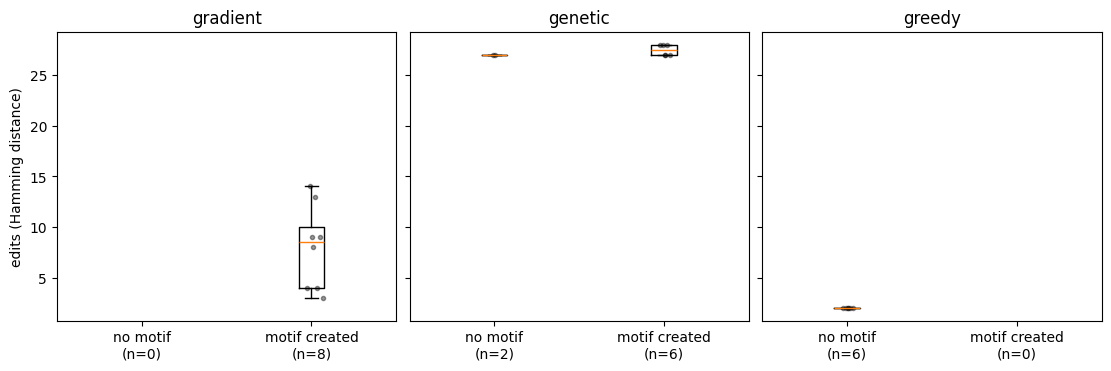

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True, layout="constrained")
for ax, m in zip(axes, METHODS):
    v = cf0[(cf0.method == m) & cf0.valid]
    groups = [v[~v.created].d_H, v[v.created].d_H]
    ax.boxplot([g for g in groups], tick_labels=[f"no motif\n(n={len(groups[0])})", f"motif created\n(n={len(groups[1])})"])
    for i, g in enumerate(groups, 1): ax.plot(np.random.default_rng(0).normal(i, 0.05, len(g)), g, ".", alpha=.4, color="k")
    ax.set(title=m); 
axes[0].set_ylabel("edits (Hamming distance)")
fig.savefig(out / "sparsity_vs_motif_tier0.png", dpi=200); plt.show()

## 7. Alignments (randomly chosen, including failures)

Queries are drawn with a fixed seed **without looking at the results**, one counterfactual per method (the first valid one). `^` marks an edited position and `[---]` a FIMO hit present in the counterfactual and absent in the original. Counterfactuals with no created hit are shown as they are: they are part of the answer.

In [11]:
def alignment(r, lo=28, hi=75):
    o, c, w = r.orig, r.seq, hi - lo
    ruler = [" "] * w
    for i in range(lo, hi):
        if i % 10 == 0 and i - lo + 2 <= w:
            for k, ch in enumerate(str(i)): ruler[i - lo + k] = ch
    fim = [" "] * w
    for (st, en, p, mt) in r.new_hits:
        a, b = max(st, lo) - lo, min(en, hi) - lo
        if b > a: fim[a:b] = list("[" + "-" * (b - a - 2) + "]" if b - a >= 2 else "|")
    ed = "".join("^" if o[i] != c[i] else " " for i in range(lo, hi))
    lines = [f"{r.method}, {r.d_H} edits, P(bound): {r.p_orig:.3f} -> {r.p1:.3f}, second model: {r.p2:.3f}",
             "pos      " + "".join(ruler), "original " + o[lo:hi], "counterf " + c[lo:hi],
             "edits    " + ed, "FIMO hit " + "".join(fim)]
    for (st, en, p, mt) in r.new_hits: lines.append(f"         created {mt or c[st:en]} at {st}-{en}, p = {p:.1e}")
    if not r.new_hits: lines.append("         no new FIMO hit")
    return "\n".join(lines)

def show_alignments(cf, qids, n=3, seed=SEED, fname=None):
    rg = np.random.default_rng(seed); txt = []
    for q in rg.choice(qids, min(n, len(qids)), replace=False):
        txt.append(f"=== query (test index) {int(q)} ===")
        for m in METHODS:
            g = cf[(cf["query"] == int(q)) & (cf.method == m) & cf.valid]
            txt.append(alignment(next(g.head(1).itertuples())) if len(g) else f"{m}: no valid counterfactual")
            txt.append("")
    s = "\n".join(txt); print(s)
    if fname: (out / fname).write_text(s)
show_alignments(cf0, qids0, fname="alignments_tier0.txt")

=== query (test index) 1011 ===
gradient, 4 edits, P(bound): 0.029 -> 0.983, second model: 0.971
pos        30        40        50        60        70   
original GTGAGATCGTTTTAGGTTAGAGAACAATTATCCTTGATTCTCTCTTC
counterf GTGAGATCGTTTTTGATAAGCGAACAATTATCCTTGATTCTCTCTTC
edits                 ^ ^ ^  ^                          
FIMO hit              [-----]                           
         created TGATAAG at 41-48, p = 9.7e-05

genetic, 27 edits, P(bound): 0.029 -> 0.973, second model: 0.971
pos        30        40        50        60        70   
original GTGAGATCGTTTTAGGTTAGAGAACAATTATCCTTGATTCTCTCTTC
counterf GTCACCTATAACATAGTTGATAAGATTTAAAACTTGGTTTGGCCTTC
edits      ^ ^^ ^^^^^^^^   ^^^^ ^^^^ ^ ^^    ^  ^^^^    
FIMO hit                  [-----]                       
         created TGATAAG at 45-52, p = 9.7e-05

greedy, 2 edits, P(bound): 0.029 -> 0.778, second model: 0.684
pos        30        40        50        60        70   
original GTGAGATCGTTTTAGGTTAGAGAACAATTATCCTTGATTCTCT

## 8. Part B: Tier 1 (CTCF/K562) transfer check

Same pipeline, same window, same k, with the E1 Tier 1 models (seed 565 explained, seed 566 for transferability). **Report only motif creation rate and transferability** from this table (PDF Section 3). Both seeds use the same data and differ in initialization and batch order only, so transferability here is weaker evidence than on Tier 0 and the report should say so. FIMO scans both strands for CTCF.

In [12]:
import sys; sys.path.insert(0, str(Path.cwd()))
from tier1_loader import load_tier1
tr1, va1, te1 = load_tier1("tier1_CTCF_K562.npz", negatives="dinuc")
cnn1b = load_cnn("e1_results/tier1_seed565/model.pt"); cnn2b = load_cnn("e1_results/tier1_seed566/model.pt")
Xte1, yte1 = te1; p1b = prob(cnn1b, Xte1)
rg = np.random.default_rng(SEED)
neg1 = np.flatnonzero((p1b < 0.5) & (yte1 == 0))
qids1 = np.sort(rg.choice(neg1, N_QUERIES, replace=False)); Xq1 = Xte1[qids1]
sub = np.sort(rg.choice(len(tr1[1]), 2000, replace=False))      # mixed-class sample defines DiCE's feature space
dice1 = build_dice(cnn1b, tr1[0][sub], tr1[1][sub])
print("Tier 1 negative test sequences scored negative:", len(neg1), "| queries:", len(qids1))
pd.DataFrame({"test_index": qids1, "seq": [to_str(s) for s in Xq1], "p_model1": p1b[qids1],
              "p_model2": prob(cnn2b, Xq1)}).to_csv(out / "queries_tier1.csv", index=False)
raw1 = run_all("tier1", cnn1b, dice1, qids1, Xq1)

Tier 1 negative test sequences scored negative: 3463 | queries: 2


100%|████████████████████████████████████████████| 1/1 [00:54<00:00, 54.80s/it]


Diverse Counterfactuals found! total time taken: 00 min 53 sec


100%|████████████████████████████████████████████| 1/1 [00:03<00:00,  3.61s/it]


query 3527: gradient: 4 CFs, 54.8s | genetic: 4 CFs, 3.6s | greedy: 4 CFs, 0.3s


100%|████████████████████████████████████████████| 1/1 [00:20<00:00, 20.98s/it]


Diverse Counterfactuals found! total time taken: 00 min 19 sec


100%|████████████████████████████████████████████| 1/1 [00:04<00:00,  4.78s/it]


query 4979: gradient: 4 CFs, 21.0s | genetic: 4 CFs, 4.8s | greedy: 4 CFs, 1.2s
Queries where DiCE raised an error: {'gradient': 0, 'genetic': 0, 'greedy': 0}


In [13]:
cf1 = evaluate(raw1, qids1, Xq1, cnn1b, cnn2b, "tier1_CTCF_K562.meme", both_strands=True)
summary1 = summarize(cf1, raw1, qids1)
cf1.drop(columns=["new_hits"]).to_csv(out / "counterfactuals_tier1.csv", index=False)
summary1.to_csv(out / "summary_tier1.csv"); print(summary1.to_string())
print("\nRequired for Tier 1:"); print(summary1.loc[["motif creation rate", "transferability to 2nd model"]].to_string())
show_alignments(cf1, qids1, fname="alignments_tier1.txt")

memelite columns: ['seq', 'start', 'end', 'strand', 'p', 'matched']
                                                    gradient                 genetic                  greedy
% valid CFs (of k per query)                             100                     100                      75
queries with no valid CF                               0 / 2                   0 / 2                   0 / 2
sparsity: median edits (IQR)                 10.0 (9.0-11.2)        26.0 (25.8-26.0)           2.0 (2.0-3.5)
fraction of 41 bp window rewritten                       24%                     63%                      5%
normalised d_H / L (median)                            0.099                   0.257                   0.020
proximity 1 - d_H/L (median)                           0.901                   0.743                   0.980
change in GC (median, IQR)            -0.030 (-0.059-+0.002)  +0.050 (+0.017-+0.069)  +0.005 (-0.015-+0.010)
diversity: mean pairwise Hamming                        14.2

## 9. Results later, compare with PDF 7.4

Questions the report has to answer (PDF 7.3):
1. Validity is expected to be about 100% for all methods, so what separates them: sparsity, motif creation, transferability?
2. Which method is *writing the motif* (edits close to the motif width, creation rate high) and which is finding an *adversarial shortcut* (few or many edits, low creation, transferability that does not track creation)? Transferability and motif creation are different questions.
3. How much of each counterfactual is padding (edits far from the created hit)? None of these methods gives a minimal explanation.
4. Tier 1 versus Tier 0: expect a lower creation rate on real peaks (co-factor motifs, repeats, indirect binding). Explain the gap rather than apologizing for it.
5. Limits to state: 30 queries, one model per tier, FIMO shows the letters are present rather than that a TF would bind, Tier 0's matrix is not independent of the generator, and the second Tier 1 model shares the data.

**Hand-off for E4:** `queries_tier*.csv` and `counterfactuals_tier*.csv` hold the input sequences and every counterfactual (method, query test index, sequence, edits). Note that E2's attributions cover positive sequences only, so E4 needs ISM and DeepLIFT recomputed on these negative query sequences.